# Kozy — Growth model, backtest & three scenarios
Our goal is to find Forecast monthly active customers, fulfilled bookings and Kozy revenue, and assess whether demand or cleaner capacity limits growth. The model uses retained customers plus marketing-driven acquisition; referrals are not separately identified. Forecasts are illustrative rather than causal estimates.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

customers = pd.read_csv('./cleaned_data/customers.csv', parse_dates=['signup_date'])
booking_requests = pd.read_csv('./cleaned_data/booking_requests.csv', parse_dates=['request_date'])
cleaners = pd.read_csv('./cleaned_data/cleaners.csv', parse_dates=['onboarded_date','deactivated_date'])
marketing_spend = pd.read_csv('./cleaned_data/marketing_spend.csv', parse_dates=['month'])

booking_requests['month'] = booking_requests.request_date.dt.to_period('M').dt.to_timestamp()
booking_requests['fulfilled'] = booking_requests.status.eq('fulfilled')
months = pd.date_range('2025-01-01','2026-06-01',freq='MS')

## 1. Historical drivers
An active customer has at least one fulfilled booking during a month.

Retention is the proportion of the previous month's active customers who book again.

Acquisition efficiency is estimated from newly active customers relative to demand marketing spend.

based on 2025 data, monthly retention is 62.3%, estimated acquisition is 81 newly active customers per €1,000 spent, and active customers complete 1.57 fulfilled jobs per month on average. Kozy earns approximately €14.58 per fulfilled job (20% take rate).

Limitation: Newly active customers are not necessarily caused by that month's marketing spend; the acquisition coefficient is descriptive, not a measured marketing return.


In [2]:
active = {m:set(booking_requests.loc[booking_requests.fulfilled & booking_requests.month.eq(m),'customer_id']) for m in months}

monthly = pd.DataFrame(index=months)
monthly['users'] = [len(active[m]) for m in months]
monthly['jobs'] = booking_requests[booking_requests.fulfilled].groupby('month').size().reindex(months,fill_value=0)
monthly['revenue'] = (booking_requests[booking_requests.fulfilled].groupby('month').price_eur.sum()*0.20).reindex(months,fill_value=0)
monthly['spend'] = marketing_spend[marketing_spend.side.eq('demand')].groupby('month').spend_eur.sum().reindex(months,fill_value=0)
monthly['cleaners'] = [((cleaners.onboarded_date < m+pd.offsets.MonthBegin(1)) & (cleaners.deactivated_date.isna() | (cleaners.deactivated_date>=m))).sum() for m in months]
monthly['retained'] = [np.nan]+[len(active[months[i]] & active[months[i-1]]) for i in range(1,len(months))]
monthly['new_active'] = monthly.users-monthly.retained

train, test = monthly.iloc[:12], monthly.iloc[12:]
retention = train.retained.iloc[1:].sum()/train.users.iloc[:-1].sum()
acquisition = train.new_active.iloc[1:].sum()/train.spend.iloc[1:].sum()
jobs_per_user = train.jobs.sum()/train.users.sum()
revenue_per_job = train.revenue.sum()/train.jobs.sum()

print(f'Retention: {retention:.1%} | New active customers per €1,000 demand spend: {1000*acquisition:.1f}')
print(f'Jobs per active customer: {jobs_per_user:.2f} | Kozy revenue/job: €{revenue_per_job:.2f}')

Retention: 62.3% | New active customers per €1,000 demand spend: 81.0
Jobs per active customer: 1.57 | Kozy revenue/job: €14.58


## 2. City-level backtest: January–June 2026
Parameters are estimated using **2025 only**. For each city, the model starts with its December 2025 active customers, then uses observed January–June 2026 demand marketing spend and available cleaner counts. Jobs are limited by that city's cleaner capacity (30 jobs per cleaner per month).

We compare the sum of city forecasts with platform totals and report errors by city. This is a conditional backtest, because test-period spend and cleaner availability are known inputs. It checks the model's city-level capacity rule but cannot prove that monthly aggregate capacity captures scheduling or neighborhood-level shortages.

City-level backtest, aggregated across cities:
        Platform MAPE  June actual  June predicted
users           12.0%       6771.0         5881.41
jobs            20.0%      11165.0         8594.85
revenue         20.0%     162669.6       125298.07

City MAPE:
          users  jobs  revenue
Paris     21.1% 28.3%    28.5%
Lyon      14.9%  7.4%     7.6%
Bordeaux  23.7% 31.7%    31.7%
Lille      6.2%  9.6%    10.0%


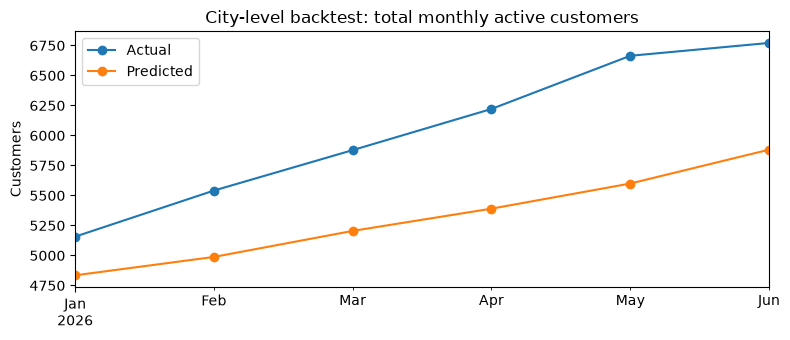

In [3]:
def simulate(start, spend, cleaners, retention, acquisition, jobs_per_user, revenue_per_job):
    rows=[]; users=float(start)
    for budget, supply in zip(spend, cleaners):
        users = users*retention + budget*acquisition
        requested_jobs = users*jobs_per_user
        fulfilled_jobs = min(requested_jobs, supply*30)
        rows.append((users, fulfilled_jobs, fulfilled_jobs*revenue_per_job, requested_jobs-fulfilled_jobs))
    return pd.DataFrame(rows, columns=['users','jobs','revenue','capacity_gap'], index=spend.index)

cities = ['Paris', 'Lyon', 'Bordeaux', 'Lille']
city_predictions, city_actuals = {}, {}

for city in cities:
    city_bookings = booking_requests[booking_requests.city.eq(city)]
    city_cleaners = cleaners[cleaners.city.eq(city)]
    city_spend = marketing_spend[marketing_spend.city.eq(city) & marketing_spend.side.eq('demand')]
    city_active = {m: set(city_bookings.loc[city_bookings.fulfilled & city_bookings.month.eq(m), 'customer_id']) for m in months}
    actual = pd.DataFrame(index=test.index)
    actual['users'] = [len(city_active[m]) for m in test.index]
    actual['jobs'] = city_bookings[city_bookings.fulfilled].groupby('month').size().reindex(test.index, fill_value=0)
    actual['revenue'] = (city_bookings[city_bookings.fulfilled].groupby('month').price_eur.sum()*0.20).reindex(test.index, fill_value=0)
    spend = city_spend.groupby('month').spend_eur.sum().reindex(test.index, fill_value=0)
    supply = pd.Series([((city_cleaners.onboarded_date < m+pd.offsets.MonthBegin(1)) &
                         (city_cleaners.deactivated_date.isna() | (city_cleaners.deactivated_date >= m))).sum()
                        for m in test.index], index=test.index)
    city_predictions[city] = simulate(len(city_active[train.index[-1]]), spend, supply,
                                      retention, acquisition, jobs_per_user, revenue_per_job)
    city_actuals[city] = actual

pred = sum(city_predictions.values())
actual = sum(city_actuals.values())

def mape(forecast, observed):
    return (forecast.sub(observed).abs() / observed.replace(0, np.nan)).mean()

comparison = pd.DataFrame({
    'Platform MAPE': {metric: mape(pred[metric], actual[metric]) for metric in ['users','jobs','revenue']},
    'June actual': actual.iloc[-1][['users','jobs','revenue']],
    'June predicted': pred.iloc[-1][['users','jobs','revenue']]
})
print('City-level backtest, aggregated across cities:')
print(comparison.round(2).to_string(formatters={'Platform MAPE': '{:.1%}'.format}))

city_errors = pd.DataFrame({city: {metric: mape(city_predictions[city][metric], city_actuals[city][metric])
                                    for metric in ['users','jobs','revenue']} for city in cities}).T
print('\nCity MAPE:')
print(city_errors.to_string(float_format=lambda x: f'{x:.1%}'))

ax = actual[['users']].rename(columns={'users':'Actual'}).join(
    pred[['users']].rename(columns={'users':'Predicted'})).plot(
    marker='o', figsize=(8,3.5), title='City-level backtest: total monthly active customers')
ax.set_ylabel('Customers'); plt.tight_layout(); plt.show()


The January–June 2026 city-level backtest has a 12.0% MAPE for active customers and 20.0% for both fulfilled jobs and revenue. In June, it predicts 5,881 active customers versus 6,771 observed, and approximately €125,298 revenue versus €162,670 observed. The plot shows that the combined city forecast underestimates activity by the end of the test period.

Revenue MAPE is 28.5% in Paris, 7.6% in Lyon, 31.7% in Bordeaux, and 10.0% in Lille. 

## 3. Twelve-month scenarios (July 2026–June 2027)
The model forecasts Paris, Lyon, Bordeaux and Lille separately, then adds their results. This prevents excess cleaner capacity in one city from automatically serving demand in another. Each city's demand marketing budget and active cleaner count are held at their June 2026 levels; a cleaner is assumed able to fulfill 30 jobs per month.

- **Pessimistic:** Retention and acquisition efficiency each **10% lower**, cleaner capacity **20% lower**.
- **Base:** Historical 2025 retention and acquisition efficiency; unchanged cleaner capacity.
- **Optimistic:** Retention and acquisition efficiency each **10% higher**, cleaner capacity **20% higher**.

The revenue plot compares monthly scenario paths under these assumptions. A higher revenue trajectory reflects stronger modeled demand, subject to city-level cleaner capacity. City-level retention, acquisition efficiency and job frequency are still approximated using platform-wide 2025 averages.


             Month 12 active customers  12-month fulfilled jobs  12-month Kozy revenue (€)  12-month city-level capacity gap (estimated)
Pessimistic                     4905.0                  88531.0                  1290635.0                                        7295.0
Base                            6348.0                 111078.0                  1619322.0                                        9231.0
Optimistic                      8343.0                 138450.0                  2018358.0                                       13242.0


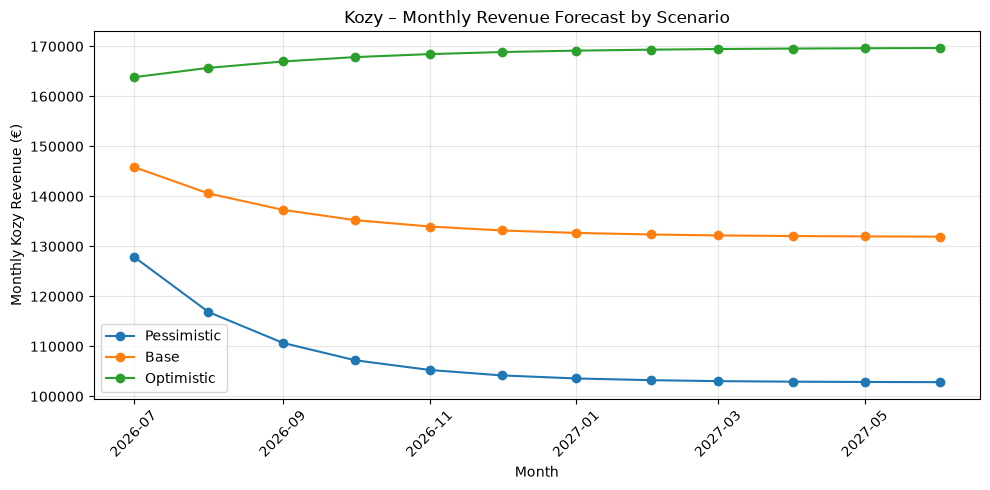

In [4]:
future = pd.date_range('2026-07-01', periods=12, freq='MS')

settings = {
    'Pessimistic': (0.90, 0.90, 0.80),
    'Base': (1, 1, 1),
    'Optimistic': (1.10, 1.10, 1.20)
}

scenarios = {}

for name, (r, a, capacity) in settings.items():
    city_forecasts = []

    for city in ['Paris', 'Lyon', 'Bordeaux', 'Lille']:
        city_bookings = booking_requests[booking_requests.city == city]
        city_spend = marketing_spend[
            (marketing_spend.city == city) &
            (marketing_spend.side == 'demand')
        ]
        city_cleaners = cleaners[cleaners.city == city]

        # Starting active customers
        start = city_bookings[
            (city_bookings.month == months[-1]) &
            (city_bookings.fulfilled)
        ].customer_id.nunique()

        # Latest monthly marketing budget
        budget = city_spend.groupby('month').spend_eur.sum().get(months[-1], 0)

        # Active cleaner capacity
        supply = (
            (city_cleaners.onboarded_date < future[0]) &
            (city_cleaners.deactivated_date.isna() |
             (city_cleaners.deactivated_date >= months[-1]))
        ).sum()

        forecast = simulate(
            start,
            pd.Series(budget, index=future),
            pd.Series(supply * capacity, index=future),
            min(retention * r, 1),
            acquisition * a,
            jobs_per_user,
            revenue_per_job
        )

        city_forecasts.append(forecast)

    scenarios[name] = sum(city_forecasts)

summary = pd.DataFrame({
    name: {
        'Month 12 active customers': v.users.iloc[-1],
        '12-month fulfilled jobs': v.jobs.sum(),
        '12-month Kozy revenue (€)': v.revenue.sum(),
        '12-month city-level capacity gap (estimated)': v.capacity_gap.sum()
    }
    for name, v in scenarios.items()
}).T

print(summary.round(0).to_string())

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for name, forecast in scenarios.items():
    plt.plot(forecast.index, forecast['revenue'],
             marker='o', label=name)

plt.title('Kozy – Monthly Revenue Forecast by Scenario')
plt.xlabel('Month')
plt.ylabel('Monthly Kozy Revenue (€)')
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [5]:
unfulfilled = booking_requests[
    booking_requests.status == 'unfulfilled'
]

print(
    unfulfilled.groupby('city').size()
    .rename('Actual unfulfilled requests')
)

city
Bordeaux      772
Lille         389
Lyon        12426
Paris        3380
Name: Actual unfulfilled requests, dtype: int64


## 4. Decision for the board
The 12-month Base forecast is **€1.62m in Kozy revenue** from approximately **111,078 fulfilled jobs**. The Optimistic scenario reaches **€2.02m** (138,450 jobs), while the Pessimistic scenario falls to **€1.29m** (88,531 jobs). The revenue plot illustrates the separation between the three paths as the assumptions compound over time.

Estimated unmet jobs are **9,231 in Base**, **13,242 in Optimistic**, and **7,295 in Pessimistic**. Unmet demand is highest in the Optimistic case because stronger customer demand can outgrow even the assumed 20% capacity increase in constrained cities. Our model, a modeled capacity gap, not a prediction of actual unfulfilled booking statuses. Historical unfulfilled requests are highest in **Lyon (12,426)**, followed by **Paris (3,380)**, **Bordeaux (772)** and **Lille (389)**; raw counts should be compared with each city's total requests before ranking shortage severity.

Our recommendation is balance demand growth with **targeted cleaner recruitment**, especially where observed unfulfilled rates and modeled capacity gaps are high. Avoid a blanket customer-only investment decision: increasing demand without matching local supply can leave more requests unmet. The model does not estimate causal returns to additional marketing or recruitment spending, and the city-level backtest remains conditional on observed marketing and cleaner counts. 
